Starting equilibration phase...
Equilibration complete. Final optimized step size d = 0.1197
Starting production phase and sampling configurations...
Saved 1000 configurations for analysis.


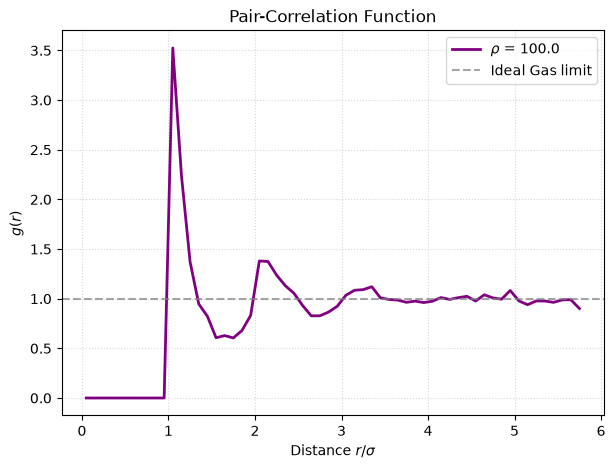

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

# ==========================================
# 1. System Parameters & Initialization
# ==========================================
#N = 64           # Number of particles (e.g., 8x8 lattice)
#sigma = 1.0      # Particle diameter[cite: 1]
#rho = 0.4        # Number density
#L = np.sqrt(N / rho)  # Box length for 2D

#d = 0.2          # Initial maximum displacement amplitude[cite: 2]
L = 1.0
N = 100
eta = 0.6
rho = N/L**2
sigma = 2*np.sqrt((eta*L)/N/np.pi)
dr = sigma/10

d = 0.2


def initialize_square_lattice(N, L):
    m = int(np.ceil(np.sqrt(N)))
    a = L / m
    positions = np.zeros((N, 2))
    count = 0
    for i in range(m):
        for j in range(m):
            if count < N:
                positions[count] = [(i + 0.5) * a, (j + 0.5) * a]
                count += 1
    return positions

def wrap_positions(positions, L):
    return positions % L

def get_distance_matrix(positions, L):
    N = len(positions)
    distances = np.zeros((N, N))
    for i in range(N):
        for j in range(i + 1, N):
            dx = positions[i, 0] - positions[j, 0]
            dy = positions[i, 1] - positions[j, 1]
            dx = dx - L * np.round(dx / L)
            dy = dy - L * np.round(dy / L)
            r_ij = np.sqrt(dx**2 + dy**2)
            distances[i, j] = r_ij
            distances[j, i] = r_ij
    return distances

def check_overlap(particle_idx, new_pos, positions, L, sigma):
    N = len(positions)
    for j in range(N):
        if j == particle_idx:
            continue
        dx = new_pos[0] - positions[j, 0]
        dy = new_pos[1] - positions[j, 1]
        dx = dx - L * np.round(dx / L)
        dy = dy - L * np.round(dy / L)
        if np.sqrt(dx**2 + dy**2) < sigma:
            return True
    return False

# Initialize positions
particle_positions = initialize_square_lattice(N, L)

initial_positions = initialize_square_lattice(N, L).copy()
particle_positions = initial_positions.copy()

# ==========================================
# 2. Equilibration Phase (with auto-tuning)
# ==========================================
print("Starting equilibration phase...")
equilibration_steps = 10000
N_MC = 1000
accepted_in_block = 0

for step in range(equilibration_steps):
    i = np.random.randint(0, N)
    old_pos = particle_positions[i].copy()
    
    delta_x = d * (np.random.rand() - 0.5)
    delta_y = d * (np.random.rand() - 0.5)
    new_pos = wrap_positions(old_pos + np.array([delta_x, delta_y]), L)
    
    if not check_overlap(i, new_pos, particle_positions, L, sigma):
        particle_positions[i] = new_pos
        accepted_in_block += 1
        
    if (step + 1) % N_MC == 0:
        acceptance_rate = accepted_in_block / N_MC
        if acceptance_rate < 0.25:
            d *= 0.95  # Decrease step size if acceptance is too low[cite: 3]
        elif acceptance_rate > 0.50:
            d *= 1.05  # Increase step size if acceptance is too high[cite: 2, 3]
        accepted_in_block = 0

print(f"Equilibration complete. Final optimized step size d = {d:.4f}")

# ==========================================
# 3. Production Phase & Configuration Sampling
# ==========================================
print("Starting production phase and sampling configurations...")
production_steps = 20000
sample_interval = 20  # Save configuration every 100 steps
saved_configs = []

for step in range(production_steps):
    i = np.random.randint(0, N)
    old_pos = particle_positions[i].copy()
    
    delta_x = d * (np.random.rand() - 0.5)
    delta_y = d * (np.random.rand() - 0.5)
    new_pos = wrap_positions(old_pos + np.array([delta_x, delta_y]), L)
    
    if not check_overlap(i, new_pos, particle_positions, L, sigma):
        particle_positions[i] = new_pos
        
    # Sample configurations periodically
    if (step + 1) % sample_interval == 0:
        saved_configs.append(particle_positions.copy())

print(f"Saved {len(saved_configs)} configurations for analysis.")

# ==========================================
# 4. Compute and Plot Pair-Correlation g(r)
# ==========================================
def compute_pair_correlation(configurations, L, sigma, dr, r_max):
    bins = np.arange(0, r_max + dr, dr)
    n_bins = len(bins) - 1
    r_values = 0.5 * (bins[:-1] + bins[1:])
    
    total_counts = np.zeros(n_bins)
    n_configs = len(configurations)
    N = len(configurations[0])
    rho = N / (L**2)
    
    for positions in configurations:
        dist_matrix = get_distance_matrix(positions, L)
        for i in range(N):
            distances = dist_matrix[i]
            distances = distances[distances > 0]
            counts, _ = np.histogram(distances, bins=bins)
            total_counts += counts
            
    avg_counts = total_counts / (n_configs * N)
    
    g_r = np.zeros(n_bins)
    for i in range(n_bins):
        r = r_values[i]
        n_ideal = rho * 2 * np.pi * r * dr  # Ideal gas reference in 2D[cite: 2]
        g_r[i] = avg_counts[i] / n_ideal
        
    return r_values, g_r

# Compute g(r) with dr = 0.1 * sigma (as suggested in project guide)[cite: 3]
dr = 0.1 * sigma
r_max = L / 2.0
r_vals, g_vals = compute_pair_correlation(saved_configs, L, sigma, dr, r_max)

# Plotting g(r)
plt.figure(figsize=(7, 5))
plt.plot(r_vals / sigma, g_vals, label=f'$\\rho$ = {rho}', color='purple', lw=2)
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.7, label='Ideal Gas limit')
plt.xlabel('Distance $r / \\sigma$')
plt.ylabel('$g(r)$')
plt.title('Pair-Correlation Function')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

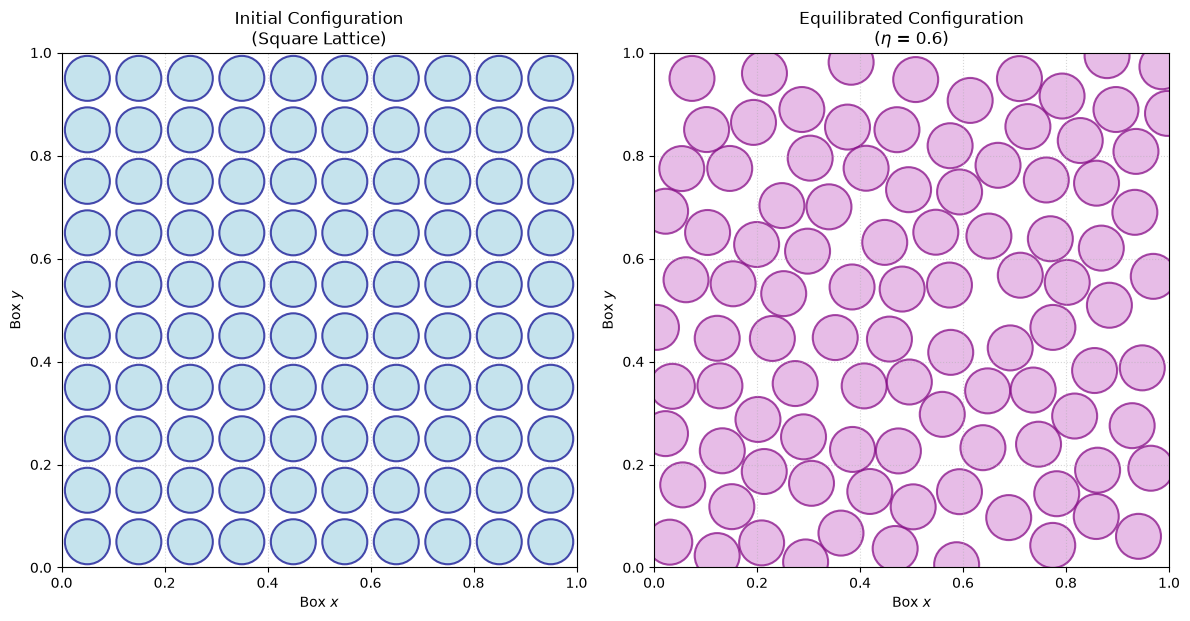

In [26]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

def plot_particle_snapshots(init_positions, final_positions, L, sigma, eta):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    
    configs = [
        (init_positions, "Initial Configuration\n(Square Lattice)", 'darkblue', 'lightblue'),
        (final_positions, f"Equilibrated Configuration\n($\\eta$ = {eta})", 'purple', 'plum')
    ]
    
    for ax, (pos_set, title, edge_col, face_col) in zip([ax1, ax2], configs):
        for pos in pos_set:
            # Draw hard disks as circles with radius = sigma / 2
            circle = Circle(pos, sigma / 2.0, edgecolor=edge_col, facecolor=face_col, alpha=0.7, linewidth=1.5)
            ax.add_patch(circle)
            
        ax.set_xlim(0, L)
        ax.set_ylim(0, L)
        ax.set_aspect('equal')
        ax.set_title(title, fontsize=12)
        ax.set_xlabel('Box $x$', fontsize=10)
        ax.set_ylabel('Box $y$', fontsize=10)
        ax.grid(True, linestyle=':', alpha=0.5)
        
    plt.tight_layout()
    plt.show()

# Run the plotting function using variables from your main block
plot_particle_snapshots(initial_positions, particle_positions, L, sigma, eta)

Running simulation for density rho = 0.4...
Running simulation for density rho = 0.7...


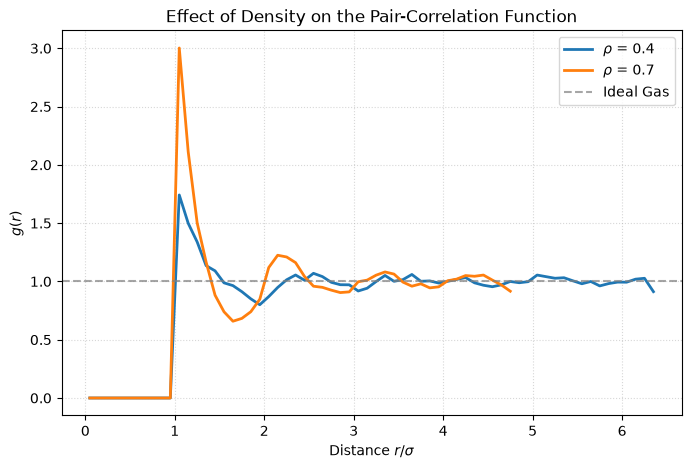

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# --- Re-use core helper functions ---
def initialize_square_lattice(N, L):
    m = int(np.ceil(np.sqrt(N)))
    a = L / m
    positions = np.zeros((N, 2))
    count = 0
    for i in range(m):
        for j in range(m):
            if count < N:
                positions[count] = [(i + 0.5) * a, (j + 0.5) * a]
                count += 1
    return positions

def wrap_positions(positions, L):
    return positions % L

def get_distance_matrix(positions, L):
    N = len(positions)
    distances = np.zeros((N, N))
    for i in range(N):
        for j in range(i + 1, N):
            dx = positions[i, 0] - positions[j, 0]
            dy = positions[i, 1] - positions[j, 1]
            dx = dx - L * np.round(dx / L)
            dy = dy - L * np.round(dy / L)
            r_ij = np.sqrt(dx**2 + dy**2)
            distances[i, j] = r_ij
            distances[j, i] = r_ij
    return distances

def check_overlap(particle_idx, new_pos, positions, L, sigma):
    N = len(positions)
    for j in range(N):
        if j == particle_idx:
            continue
        dx = new_pos[0] - positions[j, 0]
        dy = new_pos[1] - positions[j, 1]
        dx = dx - L * np.round(dx / L)
        dy = dy - L * np.round(dy / L)
        if np.sqrt(dx**2 + dy**2) < sigma:
            return True
    return False

def run_simulation(rho_val, equilibration_steps=8000, production_steps=15000):
    N = 64
    sigma = 1.0
    L = np.sqrt(N / rho_val)
    d = 0.15
    
    positions = initialize_square_lattice(N, L)
    
    # Equilibration with auto-tuning
    N_MC = 1000
    accepted_in_block = 0
    for step in range(equilibration_steps):
        i = np.random.randint(0, N)
        old_pos = positions[i].copy()
        new_pos = wrap_positions(old_pos + d * (np.random.rand(2) - 0.5), L)
        
        if not check_overlap(i, new_pos, positions, L, sigma):
            positions[i] = new_pos
            accepted_in_block += 1
            
        if (step + 1) % N_MC == 0:
            acc_rate = accepted_in_block / N_MC
            if acc_rate < 0.25: d *= 0.95
            elif acc_rate > 0.50: d *= 1.05
            accepted_in_block = 0
            
    # Production sampling
    saved_configs = []
    for step in range(production_steps):
        i = np.random.randint(0, N)
        old_pos = positions[i].copy()
        new_pos = wrap_positions(old_pos + d * (np.random.rand(2) - 0.5), L)
        
        if not check_overlap(i, new_pos, positions, L, sigma):
            positions[i] = new_pos
            
        if (step + 1) % 100 == 0:
            saved_configs.append(positions.copy())
            
    return saved_configs, L, sigma

def compute_g_r(configurations, L, sigma, dr=0.1):
    r_max = L / 2.0
    bins = np.arange(0, r_max + dr, dr)
    r_values = 0.5 * (bins[:-1] + bins[1:])
    n_bins = len(r_values)
    
    total_counts = np.zeros(n_bins)
    n_configs = len(configurations)
    N = len(configurations[0])
    rho = N / (L**2)
    
    for positions in configurations:
        dist_matrix = get_distance_matrix(positions, L)
        for i in range(N):
            distances = dist_matrix[i][dist_matrix[i] > 0]
            counts, _ = np.histogram(distances, bins=bins)
            total_counts += counts
            
    avg_counts = total_counts / (n_configs * N)
    g_r = [avg_counts[i] / (rho * 2 * np.pi * r_values[i] * dr) for i in range(n_bins)]
    return r_values, np.array(g_r)

# --- Run for Two Different Densities ---
densities = [0.4, 0.7]
plt.figure(figsize=(8, 5))

for rho in densities:
    print(f"Running simulation for density rho = {rho}...")
    configs, L, sigma = run_simulation(rho)
    r_vals, g_vals = compute_g_r(configs, L, sigma)
    plt.plot(r_vals, g_vals, label=f'$\\rho$ = {rho}', lw=2)

plt.axhline(1.0, color='gray', linestyle='--', alpha=0.7, label='Ideal Gas')
plt.xlabel('Distance $r / \\sigma$')
plt.ylabel('$g(r)$')
plt.title('Effect of Density on the Pair-Correlation Function')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()